In [1]:
# Importación de librerías y configuración inicial
import os
import json
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image

# Configuración de hiperparámetros
DATASET_DIR = "dataset"
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

print(f"Versión de TensorFlow: {tf.__version__}")

Versión de TensorFlow: 2.21.0


In [2]:
# Verificación del dataset y limpieza de archivos corruptos
# Eliminar archivos corruptos o extensiones no válidas que rompen el pipeline de TF
valid_extensions = {".jpg", ".jpeg", ".png"}
imagenes_eliminadas = 0
conteo_clases = {}

print("Iniciando verificación del dataset...")
for persona in os.listdir(DATASET_DIR):
    persona_path = os.path.join(DATASET_DIR, persona)
    if os.path.isdir(persona_path):
        conteo_clases[persona] = 0
        for file in os.listdir(persona_path):
            ext = os.path.splitext(file)[1].lower()
            filepath = os.path.join(persona_path, file)
            
            if ext not in valid_extensions:
                os.remove(filepath)
                imagenes_eliminadas += 1
                continue
                
            try:
                # Verificar integridad del archivo
                img = Image.open(filepath)
                img.verify()
                conteo_clases[persona] += 1
            except Exception:
                os.remove(filepath)
                imagenes_eliminadas += 1

print(f"Verificación completada. Archivos corruptos/inválidos eliminados: {imagenes_eliminadas}")
print("\nConteo por persona:")
for persona, count in conteo_clases.items():
    print(f" - {persona}: {count} imágenes")

Iniciando verificación del dataset...
Verificación completada. Archivos corruptos/inválidos eliminados: 0

Conteo por persona:
 - Angelo Vergara: 173 imágenes
 - Avril Lavigne: 162 imágenes
 - Krysten Ritter: 171 imágenes
 - Rami Malek: 160 imágenes
 - Shakira: 154 imágenes
 - Tom Hiddleston: 171 imágenes


In [3]:
# Carga del dataset, partición (80/20) y exportación de clases
# Carga del conjunto de entrenamiento (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    crop_to_aspect_ratio=True # Evita la distorsión de imágenes rectangulares
)

# Carga del conjunto de validación (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    crop_to_aspect_ratio=True # Evita la distorsión de imágenes rectangulares
)

# Extraer y guardar el orden de las clases para la inferencia en vivo
class_names = train_ds.class_names
num_clases = len(class_names)

with open("clases.json", "w") as f:
    json.dump(class_names, f)

print(f"\nClases detectadas ({num_clases}) y guardadas en clases.json:")
print(class_names)

Found 991 files belonging to 6 classes.
Using 793 files for training.
Found 991 files belonging to 6 classes.
Using 198 files for validation.

Clases detectadas (6) y guardadas en clases.json:
['Angelo Vergara', 'Avril Lavigne', 'Krysten Ritter', 'Rami Malek', 'Shakira', 'Tom Hiddleston']


In [4]:
# Data Augmentation y optimización del pipeline de datos
# Data Augmentation integrado en Keras (solo se activa durante model.fit)
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
    tf.keras.layers.RandomBrightness(factor=0.2),
    tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1),
], name="data_augmentation")

# Optimización de carga en memoria
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

In [5]:
# Usamos el preprocesamiento nativo de MobileNetV2 (escala de [0,255] a [-1,1])
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

# Cargar modelo base con pesos de ImageNet (sin la cabeza densa final)
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights='imagenet'
)
# Congelar la base para la primera fase de entrenamiento
base_model.trainable = False

# Construir la arquitectura completa funcional
inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)       # 1. Aumento de datos (solo actúa en entrenamiento)
x = preprocess_input(x)             # 2. Normalización a [-1, 1]
x = base_model(x, training=False)   # 3. Extracción de características (training=False congela el BatchNorm interno)

# Construir la cabeza de clasificación
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.2)(x) # Dropout al 20% para regularización
outputs = tf.keras.layers.Dense(num_clases, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,790 (8.66 MB)

 Trainable params: 10,246 (40.02 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [6]:
# Entrenamiento principal con Callbacks
# Configuración de Callbacks
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath='modelo_facial.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("Iniciando entrenamiento (Fase 1: Cabeza de clasificación)...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30, # EarlyStopping lo detendrá antes si deja de mejorar
    callbacks=callbacks
)

Iniciando entrenamiento (Fase 1: Cabeza de clasificación)...
Epoch 1/30


c:\Escuela\IA\repositorio-ia\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.5221 - loss: 1.2904
Epoch 1: val_loss improved from None to 0.66881, saving model to modelo_facial.keras

Epoch 1: finished saving model to modelo_facial.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 274ms/step - accuracy: 0.5221 - loss: 1.2904 - val_accuracy: 0.7475 - val_loss: 0.6688
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 0.7352 - loss: 0.7077
Epoch 2: val_loss improved from 0.66881 to 0.48554, saving model to modelo_facial.keras

Epoch 2: finished saving model to modelo_facial.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 252ms/step - accuracy: 0.7352 - loss: 0.7077 - val_accuracy: 0.8535 - val_loss: 0.4855
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 184ms/step - accuracy: 0.7932 - loss: 0.5449
Epoch 3: val_loss improved from 0.48554 to 0.44910, saving model to modelo_facial.keras

Epoch 3: finished saving model to modelo_facial.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 232ms/step - accuracy: 0.7932 - loss: 0.5449 - val_accuracy:

In [7]:
# Fine-Tuning (Descongelado lógico por bloques de MobileNetV2)
print("Descongelando a partir del bloque 14 para Fine-Tuning...")

# 1. Descongelar el modelo base completo temporalmente
base_model.trainable = True

# 2. Volver a congelar hasta llegar al bloque deseado (respetando la arquitectura)
fine_tune_at = "block_14_expand"
freeze = True
for layer in base_model.layers:
    if layer.name == fine_tune_at:
        freeze = False
    layer.trainable = not freeze

# 3. Recompilar con un Learning Rate inicial bajo (1e-5)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 4. Configurar nuevos Callbacks independientes
callbacks_fine = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath='modelo_facial_finetuned.keras', # ¡Nombre diferente para no sobreescribir la Fase 1!
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    # Nuevo: Reducir el LR si el modelo rebota o se estanca en el mínimo local
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10, 
    callbacks=callbacks_fine 
)

Descongelando a partir del bloque 14 para Fine-Tuning...
Epoch 1/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - accuracy: 0.6986 - loss: 0.8043
Epoch 1: val_loss improved from None to 0.27638, saving model to modelo_facial_finetuned.keras

Epoch 1: finished saving model to modelo_facial_finetuned.keras
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 273ms/step - accuracy: 0.6986 - loss: 0.8043 - val_accuracy: 0.8990 - val_loss: 0.2764 - learning_rate: 1.0000e-05
Epoch 2/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step - accuracy: 0.7503 - loss: 0.6478
Epoch 2: val_loss did not improve from 0.27638
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 262ms/step - accuracy: 0.7503 - loss: 0.6478 - val_accuracy: 0.8788 - val_loss: 0.3009 - learning_rate: 1.0000e-05
Epoch 3/10
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.7755 - loss: 0.5632
Epoch 3: val_loss did not improve from 0.27638

Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 249ms/step - accuracy: 0.7755 

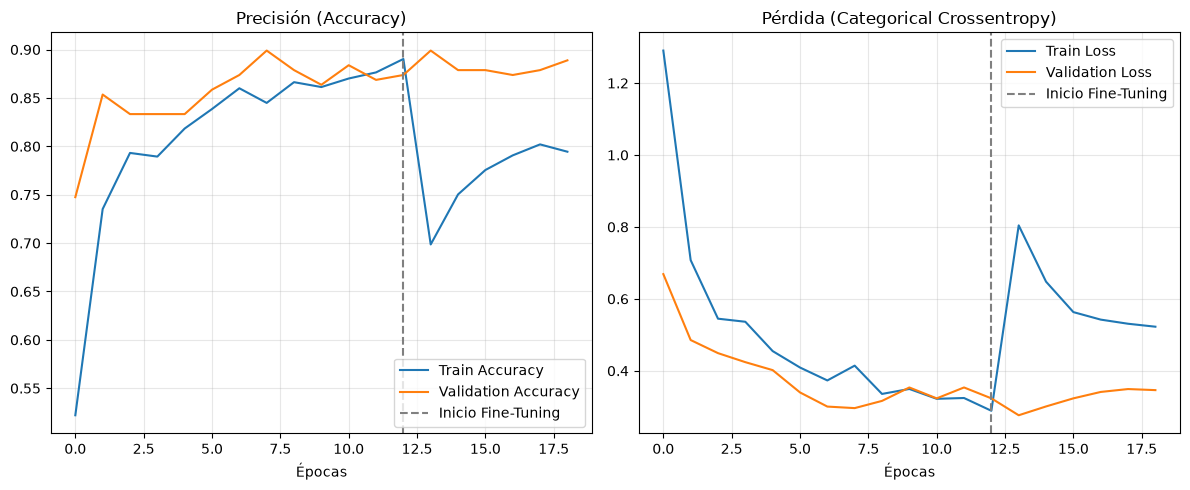


Rendimiento final en el conjunto de Validación:
Pérdida (Loss): 0.2764
Precisión (Accuracy): 89.90%

Modelo final guardado como: modelo_facial.keras


In [8]:
# Evaluación y gráficas de rendimiento
# Combinar los historiales si hiciste Fine-Tuning
acc = history.history['accuracy'] + history_fine.history['accuracy']
val_acc = history.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history.history['loss'] + history_fine.history['loss']
val_loss = history.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(12, 5))

# Gráfica de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history.history['accuracy'])-1, color='gray', linestyle='--', label='Inicio Fine-Tuning')
plt.legend(loc='lower right')
plt.title('Precisión (Accuracy)')
plt.xlabel('Épocas')
plt.grid(True, alpha=0.3)

# Gráfica de Pérdida (Loss)
plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history.history['loss'])-1, color='gray', linestyle='--', label='Inicio Fine-Tuning')
plt.legend(loc='upper right')
plt.title('Pérdida (Categorical Crossentropy)')
plt.xlabel('Épocas')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Resumen final
val_loss_final, val_acc_final = model.evaluate(val_ds, verbose=0)
print(f"\nRendimiento final en el conjunto de Validación:")
print(f"Pérdida (Loss): {val_loss_final:.4f}")
print(f"Precisión (Accuracy): {val_acc_final*100:.2f}%")
print("\nModelo final guardado como: modelo_facial.keras")

In [ ]:
import os
import json
import numpy as np
import tensorflow as tf
from PIL import Image

dataset_dir = "dataset"
carpetas_reales = sorted([
    d for d in os.listdir(dataset_dir)
    if os.path.isdir(os.path.join(dataset_dir, d))
])

with open("clases.json", "r", encoding="utf-8") as f:
    clases_prueba = json.load(f)

print("Carpetas en dataset/:", carpetas_reales)
print("Clases en clases.json:", clases_prueba)
print("¿Coinciden exactamente?:", carpetas_reales == clases_prueba)

modelo_prueba = tf.keras.models.load_model("modelo_facial.keras")
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input
img_size = (224, 224)
max_por_clase = 5

for persona in carpetas_reales:
    carpeta = os.path.join(dataset_dir, persona)
    archivos = [
        fn for fn in sorted(os.listdir(carpeta))
        if os.path.splitext(fn)[1].lower() in {".jpg", ".jpeg", ".png"}
    ][:max_por_clase]

    print(f"\n=== Carpeta real: {persona} ({len(archivos)} fotos) ===")
    for fn in archivos:
        ruta = os.path.join(carpeta, fn)
        img = Image.open(ruta).convert("RGB").resize(img_size)
        arr = np.expand_dims(np.array(img, dtype=np.float32), axis=0)

        probs = modelo_prueba.predict(arr, verbose=0)[0]
        top2_idx = np.argsort(probs)[::-1][:2]
        top2_str = " | ".join(
            f"{clases_prueba[i]} ({probs[i]*100:.1f}%)" for i in top2_idx
        )
        print(f"  {fn} -> {top2_str}")